In [ ]:
#import libraries
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
#load the dataset
df=pd.read_csv('/content/Salary_dataset.csv')
df.head()

,Unnamed: 0,YearsExperience,Salary
0,0,1.2,39344
1,1,1.4,46206
2,2,1.6,37732
3,3,2.1,43526
4,4,2.3,39892


In [ ]:
df.shape

(30, 3)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 3 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Unnamed: 0       30 non-null     int64  
 1   YearsExperience  30 non-null     float64
 2   Salary           30 non-null     int64  
dtypes: float64(1), int64(2)
memory usage: 852.0 bytes


In [ ]:
df.describe()

,Unnamed: 0,YearsExperience,Salary
count,30.000000,30.000000,30.000000
mean,14.500000,5.413333,76004.000000
std,8.803408,2.837888,27414.429785
min,0.000000,1.200000,37732.000000
25%,7.250000,3.300000,56721.750000
50%,14.500000,4.800000,65238.000000
75%,21.750000,7.800000,100545.750000
max,29.000000,10.600000,122392.000000


In [ ]:
df.isnull().sum()

,0
Unnamed: 0,0
YearsExperience,0
Salary,0


In [ ]:
#convert years experience to the nearest lower integer by removing decimal values
df['YearsExperience']=df['YearsExperience'].apply(np.floor)
df.head()

,Unnamed: 0,YearsExperience,Salary
0,0,1.0,39344
1,1,1.0,46206
2,2,1.0,37732
3,3,2.0,43526
4,4,2.0,39892


In [ ]:
#independent variable
x=df[['YearsExperience']] #df.iloc[:,:-1]
x.head()

,YearsExperience
0,1.0
1,1.0
2,1.0
3,2.0
4,2.0


In [ ]:
#dependent variable
y=df[['Salary']] #df.iloc[:,-1]
y.head()

,Salary
0,39344
1,46206
2,37732
3,43526
4,39892


In [ ]:
#split the dataset into training and testing
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [ ]:
#create the model
model=LinearRegression()

In [ ]:
#drop unnamed
df.drop('Unnamed: 0',axis=1)

,YearsExperience,Salary
0,1.0,39344
1,1.0,46206
2,1.0,37732
3,2.0,43526
4,2.0,39892
5,3.0,56643
6,3.0,60151
7,3.0,54446
8,3.0,64446
9,3.0,57190


In [ ]:
#train the model
model.fit(x_train,y_train)
print("Model trained")

Model trained


In [ ]:
#Generate predictions for training and testing datasets using the trained model
y_pred_train=model.predict(x_train)
y_pred_test=model.predict(x_test)
print("Predictions generated for both training anjd testing datasets")

Predictions generated for both training anjd testing datasets


In [ ]:
#Evaluate the performance of the model by using metrics
print("Model Evaluation Metrics")
print("Mean Absolute Error(MAE):",mean_absolute_error(y_train,y_pred_train))
print("Mean Squared Error(MSE):",mean_squared_error(y_train,y_pred_train))
print("Root Mean Squared Error(RMSE):",np.sqrt(mean_squared_error(y_train,y_pred_train)))
print("R2 Score:",r2_score(y_train,y_pred_train))

Model Evaluation Metrics
Mean Absolute Error(MAE): 4710.760416666667
Mean Squared Error(MSE): 32061037.467708338
Root Mean Squared Error(RMSE): 5662.246680224055
R2 Score: 0.9580522150250953


In [ ]:
#intercept
print("Intercept:",model.intercept_)

Intercept: [26121.625]


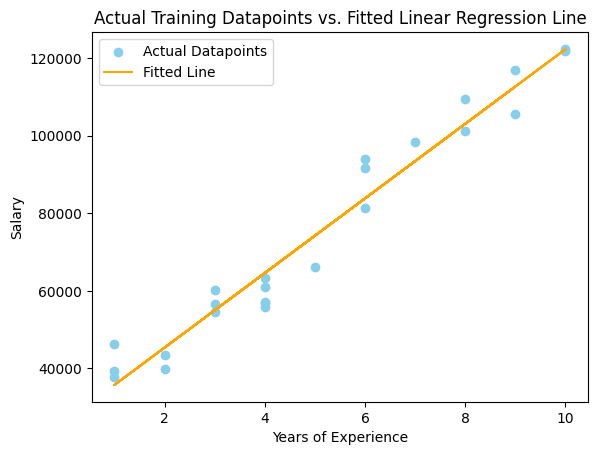

In [ ]:
#Plot actual training datapoints and fitted linear regression line for visualization
plt.scatter(x_train,y_train,color='skyblue',label='Actual Datapoints')
plt.plot(x_train,y_pred_train,color='orange',label='Fitted Line')
plt.xlabel('Years of Experience')
plt.ylabel('Salary')
plt.title('Actual Training Datapoints vs. Fitted Linear Regression Line')
plt.legend()
plt.show()

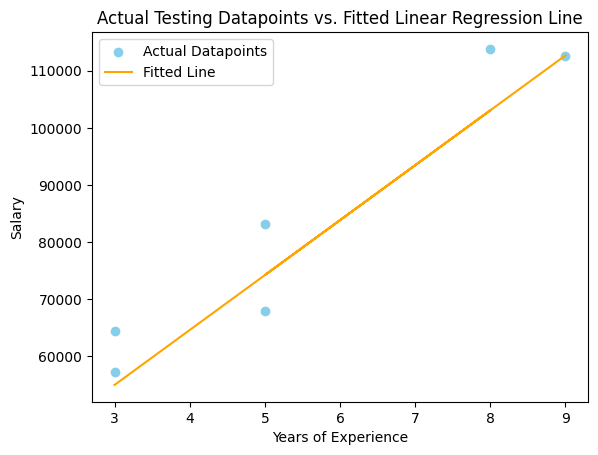

In [ ]:
#Plot testing datapoints and fitted linear regression
plt.scatter(x_test,y_test,color='skyblue',label='Actual Datapoints')
plt.plot(x_test,y_pred_test,color='orange',label='Fitted Line')
plt.xlabel('Years of Experience')
plt.ylabel('Salary')
plt.title('Actual Testing Datapoints vs. Fitted Linear Regression Line')
plt.legend()
plt.show()